In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import sys
import os

src_dir = os.path.abspath(os.path.join(os.getcwd(), '.'))
sys.path.append(src_dir)
plt.style.use(os.path.join(src_dir, 'custom_plot.mplstyle'))

# Figures used for publication

In [9]:
# Load data (assumes whitespace-separated columns)
data = np.loadtxt('data_paper_v2.dat')

# Extract columns
quarks = data[:, 0]
r1 = data[:, 1]
r2 = data[:, 2]
r2bar = data[:, 3]
T = data[:, 4]
U = data[:, 5]
V = data[:, 6]
E = data[:, 7]

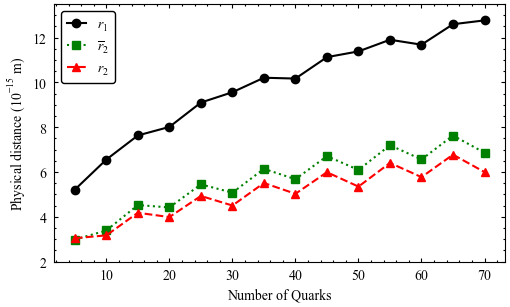

In [10]:
plt.figure()
plt.plot(quarks, r1, 'o-', label = r'$r_1$', color = 'black')
plt.plot(quarks, r2bar, 's:', label = r'$\overline{r}_2$', color = 'green')
plt.plot(quarks, r2, '^--', label = r'$r_2$', color = 'red')
plt.xlabel('Number of Quarks')
plt.ylabel(r'Physical distance ($10^{-15}$ m)')
plt.legend()
plt.ylim(2, 13.5)
plt.savefig('physical_distance_discontinuouss.pdf')
plt.tight_layout()
plt.show()

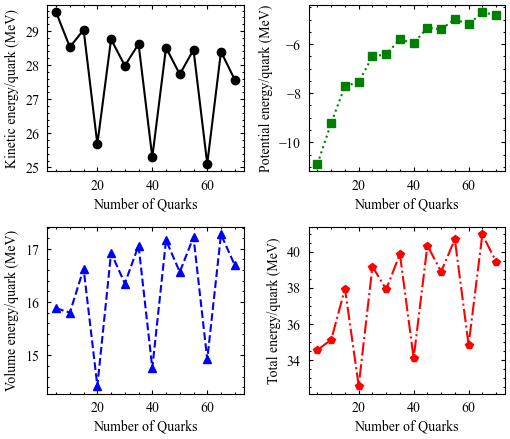

In [11]:
fig, ax = plt.subplots(2, 2, figsize = (5.3, 1.4 * 3.28))
ax[0, 0].plot(quarks, T, 'o-', color='black')
ax[0, 1].plot(quarks, U, 's:', color='green')
ax[1, 0].plot(quarks, V, '^--', color='blue')
ax[1, 1].plot(quarks, E, 'p-.', color='red')
# X labels:
ax[0, 0].set_xlabel('Number of Quarks')
ax[0, 1].set_xlabel('Number of Quarks')
ax[1, 0].set_xlabel('Number of Quarks')
ax[1, 1].set_xlabel('Number of Quarks')

# Y labels
ax[0, 0].set_ylabel('Kinetic energy/quark (MeV)')
ax[0, 1].set_ylabel('Potential energy/quark (MeV)')
ax[1, 0].set_ylabel('Volume energy/quark (MeV)')
ax[1, 1].set_ylabel('Total energy/quark (MeV)')
# ax[0, 0].legend(['T'])
# ax[0, 1].legend(['U'])
plt.tight_layout()
plt.savefig('energy_parameters.pdf')
plt.show()

### Fitting:
$$
r \propto A N^{1/3}
$$

In [36]:
# ---------------------------
# Model
# ---------------------------
def radius_model(N, A):
    return A * N**(1/3)

# ---------------------------
# Fits
# ---------------------------
A_r1, _ = curve_fit(radius_model, quarks, r1)
A_r2bar, _ = curve_fit(radius_model, quarks, r2bar)
A_r2, _ = curve_fit(radius_model, quarks, r2)

A_r1 = A_r1[0]; A_r2bar = A_r2bar[0]; A_r2 = A_r2[0]

# fitted values at measured points
r1_fit = radius_model(quarks, A_r1); r2bar_fit = radius_model(quarks, A_r2bar); r2_fit = radius_model(quarks, A_r2)

# residuals
res1 = r1 - r1_fit; res2bar = r2bar - r2bar_fit; res2 = r2 - r2_fit

# smooth fit curve
N_fit = np.linspace(np.min(quarks), np.max(quarks), 500)

### Goodness of fit:

In [37]:
# ---------------------------------------
# R²
# ---------------------------------------
def r2_score(y, yfit):
    ss_res = np.sum((y-yfit)**2)
    ss_tot = np.sum((y-np.mean(y))**2)
    return 1 - ss_res/ss_tot

print(f"r1     : A = {A_r1:.4f}, R² = {r2_score(r1,r1_fit):.5f}")
print(f"r2bar  : A = {A_r2bar:.4f}, R² = {r2_score(r2bar,r2bar_fit):.5f}")
print(f"r2     : A = {A_r2:.4f}, R² = {r2_score(r2,r2_fit):.5f}")

r1     : A = 3.0764, R² = 0.99206
r2bar  : A = 1.7571, R² = 0.92133
r2     : A = 1.5690, R² = 0.88481


### Plotting fit result

In [40]:
# Legend Labels
label_r1    = rf'$\sim {A_r1:.2f}\,N^{{1/3}}$'
label_r2bar = rf'$\sim {A_r2bar:.2f}\,N^{{1/3}}$'
label_r2    = rf'$\sim {A_r2:.2f}\,N^{{1/3}}$'

### Plot Fit results only:

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


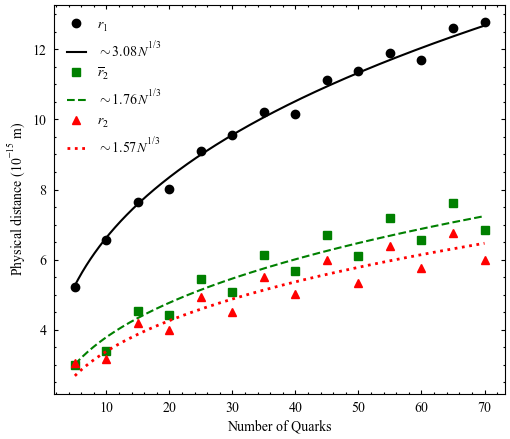

In [33]:
fig, ax1 = plt.subplots(1, 1, figsize=(5.3, 1.4 * 3.28))

# ---- Top panel ----
ax1.plot(quarks, r1, 'o', color='black', label=r'$r_1$')
ax1.plot(N_fit, radius_model(N_fit, A_r1), '-', color='black', label = label_r1 )

ax1.plot(quarks, r2bar, 's', color='green', label=r'$\overline{r}_2$')
ax1.plot(N_fit, radius_model(N_fit, A_r2bar), '--', color='green', label = label_r2bar)

ax1.plot(quarks, r2, '^', color='red', label=r'$r_2$')
ax1.plot( N_fit, radius_model(N_fit, A_r2), ':', linewidth=2, color='red', label = label_r2)

ax1.set_ylabel(r'Physical distance ($10^{-15}$ m)')
ax1.legend(frameon = False)
# ax1.set_ylim(2, 12)
ax1.set_xlabel('Number of Quarks')
plt.tight_layout()
plt.savefig('physical_distance_fit.pdf')
plt.show()

### Fit and Residual:

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


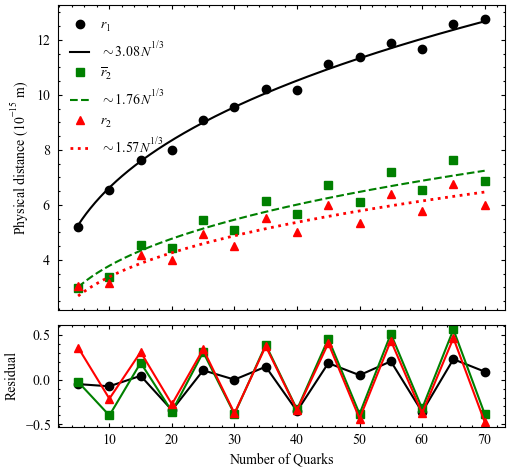

In [34]:
# ---------------------------
# Plot
# ---------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(5.3, 1.5 * 3.28), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

# ---- Top panel ----
ax1.plot(quarks, r1, 'o', color='black', label=r'$r_1$')
ax1.plot(N_fit, radius_model(N_fit, A_r1), '-', color='black', label = label_r1 )

ax1.plot(quarks, r2bar, 's', color='green', label=r'$\overline{r}_2$')
ax1.plot(N_fit, radius_model(N_fit, A_r2bar), '--', color='green', label = label_r2bar)

ax1.plot(quarks, r2, '^', color='red', label=r'$r_2$')
ax1.plot( N_fit, radius_model(N_fit, A_r2), ':', linewidth=2, color='red', label = label_r2)

ax1.set_ylabel(r'Physical distance ($10^{-15}$ m)')
ax1.legend(frameon = False)
# ax1.set_ylim(2, 12)

# ---- Residuals ----
# ax2.axhline(0, color='k', lw=1)
ax2.plot(quarks, res1, 'o-', color='black', label=r'$r_1$')
ax2.plot(quarks, res2bar, 's-', color='green', label=r'$\overline{r}_2$')
ax2.plot(quarks, res2, '^-', color='red', label=r'$r_2$')
ax2.set_xlabel('Number of Quarks')
ax2.set_ylabel('Residual')
plt.tight_layout()
plt.savefig('physical_distance_fit_residuals.pdf')
plt.show()

### In terms of Percentage:

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


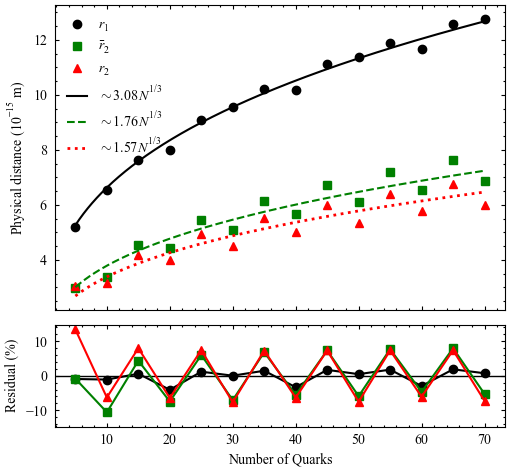

In [42]:
# ---------------------------------------
# Fractional residuals (%)
# ---------------------------------------
frac1 = 100*(r1 - r1_fit)/r1_fit
frac2bar = 100*(r2bar - r2bar_fit)/r2bar_fit
frac2 = 100*(r2 - r2_fit)/r2_fit

# ---------------------------------------
# Plot
# ---------------------------------------
fig, (ax1, ax2) = plt.subplots( 2, 1, figsize=(5.3, 1.5 * 3.28), sharex=True, gridspec_kw={'height_ratios':[3,1]} )

# ===== Main plot =====
ax1.plot(quarks, r1, 'o', color='black', label=r'$r_1$')
ax1.plot(quarks, r2bar, 's', color='green', label=r'$\bar r_2$')
ax1.plot(quarks, r2, '^', color='red', label=r'$r_2$')

ax1.plot( N_fit, radius_model(N_fit, A_r1), '-', color='black', label=label_r1 )

ax1.plot( N_fit, radius_model(N_fit, A_r2bar), '--', color='green', label=label_r2bar )

ax1.plot( N_fit, radius_model(N_fit, A_r2), ':', lw=2, color='red', label=label_r2 )

ax1.set_ylabel(r'Physical distance ($10^{-15}$ m)')
ax1.legend(frameon = False)
# ax1.grid(alpha=0.3)

# ===== Fractional residuals =====
ax2.axhline(0, color='k', lw=1)
ax2.plot(quarks, frac1, 'o-', color='black')
ax2.plot(quarks, frac2bar, 's-', color='green')
ax2.plot(quarks, frac2, '^-', color='red')

ax2.set_ylabel('Residual (%)')
ax2.set_xlabel('Number of Quarks')
# ax2.grid(alpha=0.3)

# optional symmetric limits
maxdev = np.max(np.abs(np.concatenate([frac1, frac2bar, frac2]) ) )
ax2.set_ylim(-1.1*maxdev, 1.1*maxdev)
plt.tight_layout()
plt.savefig('physical_distance_scaling_fractional_residuals.pdf', bbox_inches='tight' )
plt.show()

### Comparison of results between two different strong coupling constant:

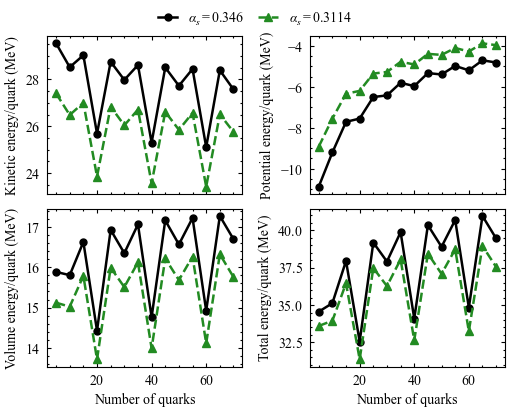

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# -------------------------
# Load alpha_1 data
# -------------------------
data1 = np.loadtxt('data_paper_v2.dat')

quarks = data1[:, 0]

r1    = data1[:, 1]
r2    = data1[:, 2]
r2bar = data1[:, 3]

T1 = data1[:, 4]
U1 = data1[:, 5]
V1 = data1[:, 6]
E1 = data1[:, 7]

# -------------------------
# Load alpha_2 data
# -------------------------
data2 = np.loadtxt('data_paper_new.dat')

T2 = data2[:, 1]
U2 = data2[:, 2]
V2 = data2[:, 3]
E2 = data2[:, 4]

# -------------------------
# Figure setup
# -------------------------
fig, ax = plt.subplots(
    2, 2,
    figsize=(5.3, 1.3 * 3.28),
    sharex=True
)

# Colors for each quantity
colors = {
    'T': 'black',
    'U': 'forestgreen',
    'V': 'royalblue',
    'E': 'crimson'
}

lw = 1.8
ms = 5

# alpha_1 (black)
ax[0, 0].plot(quarks, T1, 'o-', color='black', lw=lw, ms=ms)
ax[0, 1].plot(quarks, U1, 'o-', color='black', lw=lw, ms=ms)
ax[1, 0].plot(quarks, V1, 'o-', color='black', lw=lw, ms=ms)
ax[1, 1].plot(quarks, E1, 'o-', color='black', lw=lw, ms=ms)

# alpha_2 (green)
ax[0, 0].plot(quarks, T2, '^--', color='forestgreen', lw=lw)
ax[0, 1].plot(quarks, U2, '^--', color='forestgreen', lw=lw)
ax[1, 0].plot(quarks, V2, '^--', color='forestgreen', lw=lw)
ax[1, 1].plot(quarks, E2, '^--', color='forestgreen', lw=lw)

# -------------------------
# Axis labels
# -------------------------
ax[0, 0].set_ylabel('Kinetic energy/quark (MeV)')
ax[0, 1].set_ylabel('Potential energy/quark (MeV)')
ax[1, 0].set_ylabel('Volume energy/quark (MeV)')
ax[1, 1].set_ylabel('Total energy/quark (MeV)')

ax[1, 0].set_xlabel('Number of quarks')
ax[1, 1].set_xlabel('Number of quarks')

# -------------------------
# Common legend
# -------------------------
legend_handles = [
    Line2D(
        [0], [0],
        color='black',
        marker='o',
        lw=lw,
        ms=ms,
        label=r'$\alpha_s = 0.346$'
    ),
    Line2D(
        [0], [0],
        color='forestgreen',
        marker='^',
        ls='--',
        lw=lw,
        label=r'$\alpha_s = 0.3114$'
    )
]

fig.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.995),
    ncol=2,
    frameon=False,
    fontsize=10
)

# -------------------------
# Layout
# -------------------------
plt.tight_layout(
    rect=[0, 0, 1, 0.94]
)

plt.savefig(
    'energy_parameters_comparison.pdf',
    bbox_inches='tight'
)

plt.show()

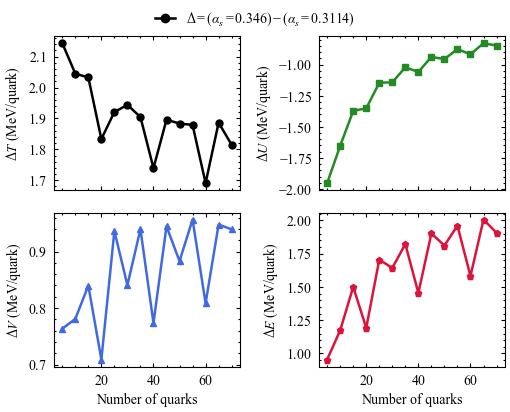

In [26]:
# ==========================================
# Differences
# ==========================================

dT = T1 - T2
dU = U1 - U2
dV = V1 - V2
dE = E1 - E2

fig2, ax2 = plt.subplots(
    2, 2,
    figsize=(5.3, 1.3 * 3.28),
    sharex=True
)

ax2[0,0].plot(quarks, dT, 'o-', color='black', lw=lw, ms=ms)
ax2[0,1].plot(quarks, dU, 's-', color='forestgreen', lw=lw, ms=ms)
ax2[1,0].plot(quarks, dV, '^-', color='royalblue', lw=lw, ms=ms)
ax2[1,1].plot(quarks, dE, 'p-', color='crimson', lw=lw, ms=ms)

# # Zero reference lines
# for a in ax2.flat:
#     a.axhline(0, color='gray', ls='--', lw=1)
#     a.minorticks_on()

# Labels
ax2[0,0].set_ylabel(r'$\Delta T$ (MeV/quark)')
ax2[0,1].set_ylabel(r'$\Delta U$ (MeV/quark)')
ax2[1,0].set_ylabel(r'$\Delta V$ (MeV/quark)')
ax2[1,1].set_ylabel(r'$\Delta E$ (MeV/quark)')

ax2[1,0].set_xlabel('Number of quarks')
ax2[1,1].set_xlabel('Number of quarks')

# Common legend
fig2.legend(
    [
        Line2D([0],[0], color='black', marker='o', lw=lw)
    ],
    [
        r'$\Delta = (\alpha_s=0.346)-(\alpha_s=0.3114)$'
    ],
    loc='upper center',
    bbox_to_anchor=(0.5,0.995),
    frameon=False
)

plt.tight_layout(rect=[0,0,1,0.94])

plt.savefig(
    'energy_parameter_difference.pdf',
    bbox_inches='tight'
)

plt.show()